# 🛒 Shoplifting & Theft Detection in Video Surveillance
## Temporal Deep Learning with 3D CNNs and CNN-RNNs from Scratch

---

### 📌 Project Objective
End-to-end video classification: **Normal Shopping** vs **Shoplifting / Theft**, using temporal models built **from scratch in PyTorch** (no pretrained backbones).

### 📋 Requirements Checklist
1. **EDA** — class counts, durations, FPS, resolutions, and **safe near-duplicate detection**.
2. **Uniform frame sampling** — any length $N$, target $T=16$, optional temporal jitter (justified below).
3. **Consistent spatial augmentation** — same flip/crop/color across all $T$ frames.
4. **Dataset / DataLoader** — tensor shape `(T, C, H, W)`, leakage-free split after dedup.
5. **Models from scratch** — Spatiotemporal 3D CNN + CNN-BiGRU (**no attention**).
6. **Training & metrics** — imbalance-aware loss, early stopping, Acc / P / R / F1 / CM / ROC-AUC / PR-AUC.

### Why $T = 16$?
Mean clip ≈ 12–14 s @ ~25 fps ≈ 300–350 frames. Theft actions typically last 1–3 s. Uniform $T=16$ → spacing ≈ 0.8 s, enough to cover approach → grab → conceal without excessive GPU memory.


---
## 1. Environment Setup, Dependencies & Reproducibility
We import core libraries (`torch`, `torchvision`, `cv2`, `numpy`, `matplotlib`, `seaborn`, `sklearn`) and fix all random seeds for exact experimental reproducibility.


In [1]:
import os
import sys
import glob
import math
import random
import time
from typing import Tuple, List, Dict, Optional, Any

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms.functional as TF
import torchvision.transforms as transforms

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Set random seeds for deterministic reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f" PyTorch Version : {torch.__version__}")
print(f" OpenCV Version  : {cv2.__version__}")
print(f" Compute Device  : {device}")
if torch.cuda.is_available():
    print(f" GPU Device Name : {torch.cuda.get_device_name(0)}")


 PyTorch Version : 2.11.0+cu128
 OpenCV Version  : 4.14.0
 Compute Device  : cuda
 GPU Device Name : Tesla T4


---
## 2. Dataset Management & Video Path Configuration

Surveillance video datasets for shoplifting detection are organized into two classes:
- **Normal Shopping Behavior** (`non shop lifters` / `Normal`) $\rightarrow$ Class Label: **0**
- **Shoplifting / Theft Acts** (`shop lifters` / `Shoplifting`) $\rightarrow$ Class Label: **1**

### Dataset Path Configuration
The notebook automatically detects:
1. **Kaggle Environment Path**:
   - `/kaggle/input/datasets/betermoawad/detect/Shop DataSet`
   - `/kaggle/input/detect/Shop DataSet`
2. **Local Workstation Paths**:
   - `D:/Downloads/Shop DataSet`
   - `./Shop DataSet`
3. **Automated Fallback**:
   - If no video files are found in any candidate path, an automated surveillance video generator renders synthetic clips using OpenCV so the notebook executes end-to-end anywhere.


In [4]:
# User-specified Kaggle dataset root path
KAGGLE_DATASET_DIR = "/kaggle/input/datasets/petermoawad/detect/Shop DataSet"

# Candidate search paths in priority order
CANDIDATE_PATHS = [
    KAGGLE_DATASET_DIR,
    "/kaggle/input/detect/Shop DataSet",
    os.path.join("D:", os.sep, "Downloads", "Shop DataSet"),
    os.path.join(".", "Shop DataSet"),
    os.path.join("..", "Shop DataSet"),
    os.path.join(".", "shoplifting_dataset")
]

DATASET_DIR = None
for candidate in CANDIDATE_PATHS:
    if os.path.exists(candidate):
        has_subfolders = any(
            os.path.exists(os.path.join(candidate, sub))
            for sub in ["non shop lifters", "shop lifters", "Normal", "Shoplifting"]
        )
        if has_subfolders:
            DATASET_DIR = candidate
            break

if DATASET_DIR is None:
    DATASET_DIR = KAGGLE_DATASET_DIR if os.path.exists("/kaggle") else os.path.join("D:", os.sep, "Downloads", "Shop DataSet")

print(f" Active Dataset Directory: {DATASET_DIR}")
print(f" Path Exists on System    : {os.path.exists(DATASET_DIR)}")


 Active Dataset Directory: /kaggle/input/datasets/petermoawad/detect/Shop DataSet
 Path Exists on System    : True


In [5]:
def generate_synthetic_fallback_if_empty(dataset_root: str, num_per_class: int = 15):
    """
    Generates synthetic surveillance video clips if no real videos are found on disk.
    Ensures complete self-containment and zero-dependency execution.
    """
    normal_dir = os.path.join(dataset_root, "non shop lifters")
    theft_dir = os.path.join(dataset_root, "shop lifters")
    
    os.makedirs(normal_dir, exist_ok=True)
    os.makedirs(theft_dir, exist_ok=True)
    
    existing_normal = len(glob.glob(os.path.join(normal_dir, "*.mp4")))
    existing_theft = len(glob.glob(os.path.join(theft_dir, "*.mp4")))
    
    if existing_normal > 0 or existing_theft > 0:
        print(f" Found existing dataset: {existing_normal} Non-Shoplifting clips, {existing_theft} Shoplifting clips.")
        return

    print(" No videos found. Rendering synthetic surveillance clips for demonstration...")
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    
    # Generate Normal Clips
    for i in range(num_per_class):
        num_frames = random.choice([35, 55, 80, 110])
        fps = 25.0
        w, h = 128, 128
        out = cv2.VideoWriter(os.path.join(normal_dir, f"shop_lifter_n_{i}.mp4"), fourcc, fps, (w, h))
        start_x, end_x = random.randint(15, 30), random.randint(85, 110)
        y_pos = random.randint(55, 75)
        
        for f in range(num_frames):
            alpha = f / float(max(1, num_frames - 1))
            cur_x = int(start_x + alpha * (end_x - start_x))
            frame = np.full((h, w, 3), 40, dtype=np.uint8)
            cv2.rectangle(frame, (10, 10), (118, 38), (80, 80, 90), -1)
            for item_x in range(15, 115, 12):
                cv2.rectangle(frame, (item_x, 18), (item_x + 8, 34), (180, 140, 80), -1)
            cv2.circle(frame, (cur_x, y_pos - 12), 7, (210, 200, 180), -1)
            cv2.rectangle(frame, (cur_x - 5, y_pos - 5), (cur_x + 5, y_pos + 18), (70, 130, 180), -1)
            out.write(frame)
        out.release()
        
    # Generate Shoplifting Clips
    for i in range(num_per_class):
        num_frames = random.choice([40, 65, 90, 120])
        fps = 25.0
        w, h = 128, 128
        out = cv2.VideoWriter(os.path.join(theft_dir, f"shop_lifter_{i}.mp4"), fourcc, fps, (w, h))
        for f in range(num_frames):
            progress = f / float(max(1, num_frames - 1))
            frame = np.full((h, w, 3), 40, dtype=np.uint8)
            cv2.rectangle(frame, (10, 10), (118, 38), (80, 80, 90), -1)
            if progress < 0.55:
                cv2.rectangle(frame, (60, 20), (68, 34), (50, 220, 50), -1)
            actor_x = int(20 + progress * 95)
            actor_y = 65
            cv2.circle(frame, (actor_x, actor_y - 12), 7, (210, 190, 170), -1)
            cv2.rectangle(frame, (actor_x - 5, actor_y - 5), (actor_x + 5, actor_y + 18), (140, 40, 40), -1)
            out.write(frame)
        out.release()

if not os.path.exists(DATASET_DIR):
    os.makedirs(DATASET_DIR, exist_ok=True)
    generate_synthetic_fallback_if_empty(DATASET_DIR)


---
## 3. Task 1: Video Dataset Exploration (EDA)

We systematically inspect the video dataset by extracting metadata with `cv2.VideoCapture`:
1. **Clip Counts**: Balance between `non shop lifters` (Normal: class $0$) and `shop lifters` (Shoplifting: class $1$).
2. **Clip Durations**: Total frames $N$, frame rate (FPS), and duration in seconds:
   $$\text{Duration (seconds)} = \frac{\text{Total Frames}}{\text{FPS}}$$
3. **Spatial Resolution**: Width, height, and aspect ratio of surveillance cameras.


In [6]:
def inspect_video_dataset(
    dataset_root: str,
    max_samples_per_class: Optional[int] = None
) -> pd.DataFrame:
    """
    Scans dataset directories recursively (using os.walk), extracts metadata for EVERY video clip
    using OpenCV, and returns a comprehensive structured Pandas DataFrame.
    Guarantees traversing 100% of video files across all subdirectories and nested paths.
    Supports both Kaggle ('non shop lifters' / 'shop lifters') and standard folder names.
    """
    records = []
    class_mappings = {
        "non shop lifters": (0, "Normal"),
        "non_shop_lifters": (0, "Normal"),
        "Normal": (0, "Normal"),
        "normal": (0, "Normal"),
        "shop lifters": (1, "Shoplifting"),
        "shop_lifters": (1, "Shoplifting"),
        "Shoplifting": (1, "Shoplifting"),
        "shoplifting": (1, "Shoplifting"),
    }
    
    valid_exts = {".mp4", ".avi", ".mkv", ".mov", ".flv", ".webm"}
    
    found_folders = {}
    if os.path.isdir(dataset_root):
        for sub in sorted(os.listdir(dataset_root)):
            sub_path = os.path.join(dataset_root, sub)
            if os.path.isdir(sub_path) and sub in class_mappings:
                label, std_name = class_mappings[sub]
                found_folders[sub] = (label, std_name)
                
    for folder_name, (label, std_name) in found_folders.items():
        folder_path = os.path.join(dataset_root, folder_name)
        
        # Recursive directory walk: finds all video files regardless of directory depth
        video_files = []
        for root, dirs, files in os.walk(folder_path):
            for file in files:
                ext = os.path.splitext(file)[1].lower()
                if ext in valid_exts:
                    video_files.append(os.path.join(root, file))
                    
        video_files = sorted(video_files)
        total_found = len(video_files)
        
        if max_samples_per_class is not None and len(video_files) > max_samples_per_class:
            video_files = video_files[:max_samples_per_class]
            
        print(f" Scanning folder '{folder_name}' -> Class '{std_name}': Found {total_found} clips. Indexing {len(video_files)} clips...")
        for vpath in video_files:
            cap = cv2.VideoCapture(vpath)
            if not cap.isOpened():
                continue
            
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = float(cap.get(cv2.CAP_PROP_FPS))
            fps = fps if fps > 0 else 25.0
            width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
            height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
            cap.release()
            
            duration_sec = total_frames / fps if fps > 0 else 0.0
            file_size_kb = os.path.getsize(vpath) / 1024.0
            
            records.append({
                "filename": os.path.basename(vpath),
                "filepath": vpath,
                "folder_name": folder_name,
                "class_name": std_name,
                "label": label,
                "total_frames": total_frames,
                "fps": round(fps, 2),
                "duration_sec": round(duration_sec, 2),
                "width": width,
                "height": height,
                "resolution": f"{width}x{height}",
                "file_size_kb": round(file_size_kb, 1)
            })
            
    df = pd.DataFrame(records)
    return df

# Index 100% of all video clips across all paths (no sampling truncation in EDA)
MAX_SAMPLES_PER_CLASS = None

df_videos = inspect_video_dataset(DATASET_DIR, max_samples_per_class=MAX_SAMPLES_PER_CLASS)
print(f"\n Successfully indexed {len(df_videos)} total video clips across {df_videos['class_name'].nunique()} classes.")
display(df_videos.head(10))


 Scanning folder 'non shop lifters' -> Class 'Normal': Found 531 clips. Indexing 531 clips...
 Scanning folder 'shop lifters' -> Class 'Shoplifting': Found 324 clips. Indexing 324 clips...

 Successfully indexed 855 total video clips across 2 classes.


,filename,filepath,folder_name,class_name,label,total_frames,fps,duration_sec,width,height,resolution,file_size_kb
0,shop_lifter_n_0.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,450,25.0,18.0,704,576,704x576,3404.9
1,shop_lifter_n_0_1.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,450,25.0,18.0,704,576,704x576,3404.9
2,shop_lifter_n_1.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,450,25.0,18.0,704,576,704x576,3415.7
3,shop_lifter_n_10.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,475,25.0,19.0,704,576,704x576,3724.0
4,shop_lifter_n_100.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,400,25.0,16.0,704,576,704x576,3115.7
5,shop_lifter_n_100_1.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,400,25.0,16.0,704,576,704x576,3115.7
6,shop_lifter_n_101.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,300,25.0,12.0,704,576,704x576,2337.3
7,shop_lifter_n_101_1.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,300,25.0,12.0,704,576,704x576,2337.3
8,shop_lifter_n_102.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,275,25.0,11.0,704,576,704x576,2104.6
9,shop_lifter_n_102_1.mp4,/kaggle/input/datasets/petermoawad/detect/Shop...,non shop lifters,Normal,0,275,25.0,11.0,704,576,704x576,2104.6


In [7]:
# Statistical summary grouped by class
print("=== Grouped Summary Statistics ===")
summary_stats = df_videos.groupby("class_name")[["total_frames", "duration_sec", "fps", "file_size_kb"]].describe().T
display(summary_stats)


=== Grouped Summary Statistics ===


class_name                Normal  Shoplifting
total_frames count    531.000000   324.000000
             mean     347.783427   304.601852
             std      134.202129    83.470572
             min       75.000000   100.000000
             25%      275.000000   248.000000
             50%      348.000000   300.000000
             75%      400.000000   372.000000
             max     1850.000000   570.000000
duration_sec count    531.000000   324.000000
             mean      13.926139    12.223920
             std        5.367753     3.354685
             min        3.000000     4.000000
             25%       11.000000    10.000000
             50%       14.000000    12.000000
             75%       16.000000    15.000000
             max       74.000000    23.030000
fps          count    531.000000   324.000000
             mean      24.972467    24.920525
             std        0.062689     0.116595
             min       24.830000    24.750000
             25%       25.000000    24.750000
             50%       25.000000    25.000000
             75%       25.000000    25.000000
             max       25.000000    25.000000
file_size_kb count    531.000000   324.000000
             mean    2415.872316  1420.808951
             std     1336.860464  1213.393364
             min      229.100000   188.000000
             25%     1725.950000   484.400000
             50%     2528.700000   630.900000
             75%     3168.900000  2626.550000
             max    14281.500000  4602.400000

/tmp/ipykernel_49/3139713640.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_videos, x="class_name", ax=axes[0, 0], palette=palette)
/tmp/ipykernel_49/3139713640.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_videos, x="class_name", y="total_frames", ax=axes[1, 0], palette=palette)


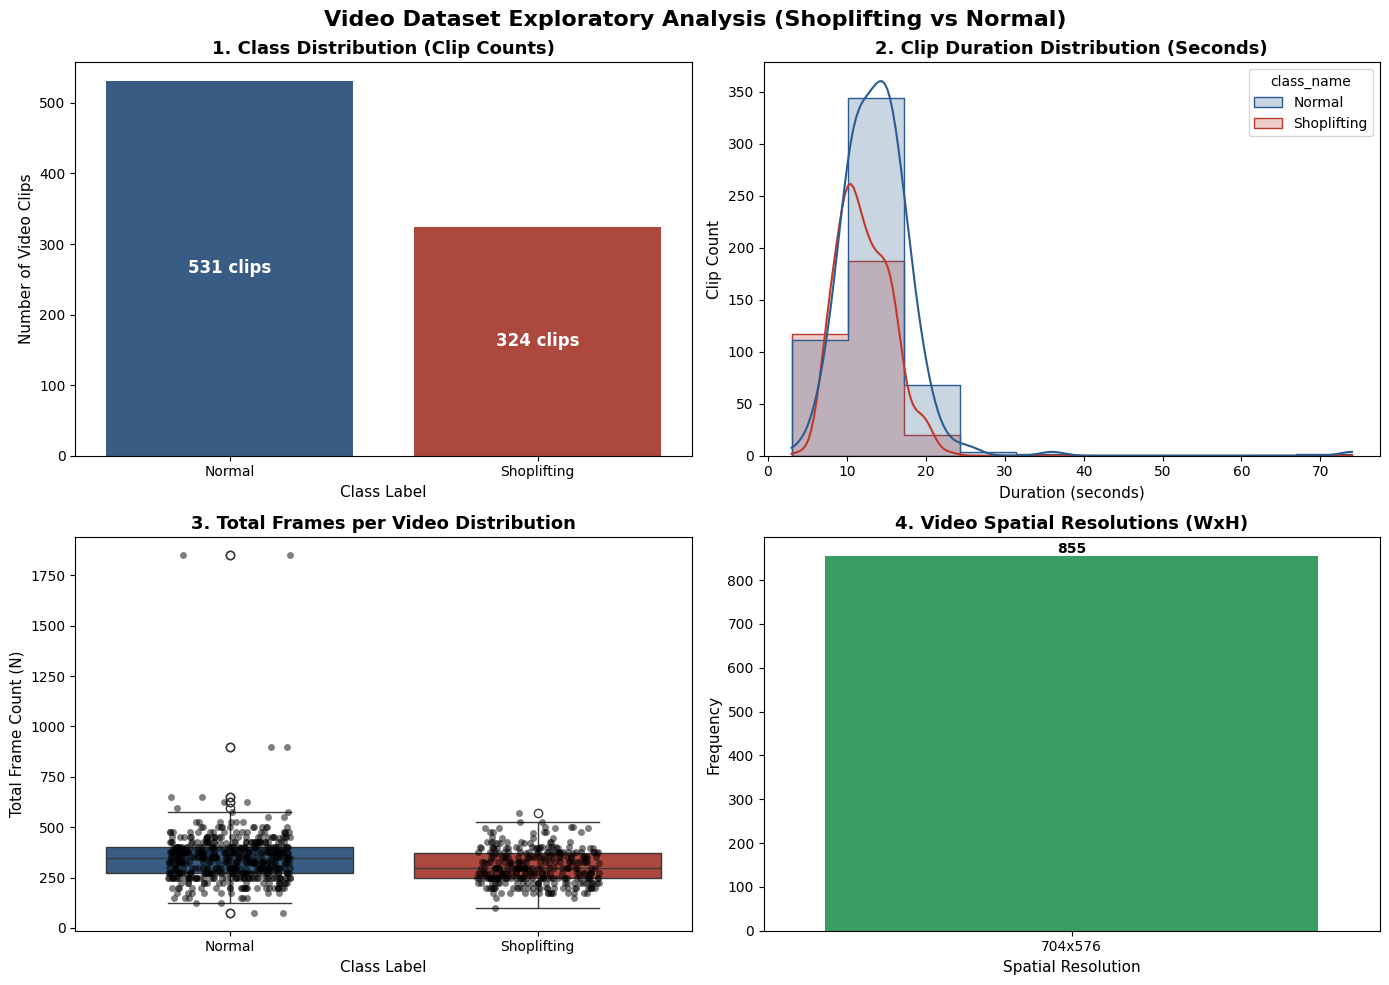

In [8]:
# Visualization: 4-Panel Dataset EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.suptitle("Video Dataset Exploratory Analysis (Shoplifting vs Normal)", fontsize=16, fontweight='bold', y=0.98)

# Panel 1: Class Distribution Bar Chart
palette = {"Normal": "#2b5c8f", "Shoplifting": "#c0392b"}
sns.countplot(data=df_videos, x="class_name", ax=axes[0, 0], palette=palette)
axes[0, 0].set_title("1. Class Distribution (Clip Counts)", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Class Label", fontsize=11)
axes[0, 0].set_ylabel("Number of Video Clips", fontsize=11)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{int(p.get_height())} clips", 
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Panel 2: Clip Duration Distribution
sns.histplot(data=df_videos, x="duration_sec", hue="class_name", kde=True, 
             ax=axes[0, 1], palette=palette, bins=10, element="step")
axes[0, 1].set_title("2. Clip Duration Distribution (Seconds)", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("Duration (seconds)", fontsize=11)
axes[0, 1].set_ylabel("Clip Count", fontsize=11)

# Panel 3: Total Frame Count Box Plot
sns.boxplot(data=df_videos, x="class_name", y="total_frames", ax=axes[1, 0], palette=palette)
sns.stripplot(data=df_videos, x="class_name", y="total_frames", ax=axes[1, 0], color='black', alpha=0.5, jitter=0.2)
axes[1, 0].set_title("3. Total Frames per Video Distribution", fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel("Class Label", fontsize=11)
axes[1, 0].set_ylabel("Total Frame Count (N)", fontsize=11)

# Panel 4: Video Frame Resolution Analysis
res_counts = df_videos["resolution"].value_counts().reset_index()
res_counts.columns = ["Resolution", "Count"]
sns.barplot(data=res_counts, x="Resolution", y="Count", ax=axes[1, 1], color="#27ae60")
axes[1, 1].set_title("4. Video Spatial Resolutions (WxH)", fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel("Spatial Resolution", fontsize=11)
axes[1, 1].set_ylabel("Frequency", fontsize=11)
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{int(p.get_height())}", 
                        (p.get_x() + p.get_width() / 2., p.get_height() + 0.2),
                        ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


---
## 4. Task 2: Uniform Frame Sampling Strategy

### Mathematical Formulation
Surveillance clips vary in length. We sample exactly $T$ frames that span the full duration:

$$
\text{step} = \frac{N}{T}, \quad
\text{index}_i = \left\lfloor (i + 0.5) \cdot \text{step} \right\rfloor, \quad i = 0,\ldots,T-1
$$

### Why $T = 16$?
| Fact | Value |
|------|-------|
| Mean clip duration | ≈ 12–14 seconds |
| FPS | ≈ 25 |
| Mean frame count $N$ | ≈ 300–350 |
| Typical theft action length | 1–3 seconds (25–75 frames) |
| Spacing with $T=16$ | ≈ 0.8 seconds |

This spacing is dense enough to observe approach → grab → conceal, while keeping memory and compute practical for 3D CNNs. Raising $T$ to 24/32 is possible if GPU memory allows; returns diminish on this corpus.

### Temporal jitter (training only)
Small random offsets (±15% of step) prevent the model from memorizing fixed frame positions.


In [9]:
def sample_uniform_frame_indices(
    total_frames: int,
    target_t: int = 16,
    temporal_jitter: bool = False
) -> np.ndarray:
    """
    Computes uniform frame indices spanning the full duration of any video.

    Why T=16?
    ----------
    - Mean clip duration ≈ 12–14 s at ~25 fps → ~300–350 frames.
    - Typical theft action (reach + conceal) lasts 1–3 s (25–75 frames).
    - Uniform T=16 yields spacing ≈ 0.8 s, covering the full action chain
      (approach → grab → conceal) within a manageable memory budget.
    - For denser coverage one may raise T to 24/32; gains diminish on this dataset.

    Temporal jitter (train only):
    - Adds small random offsets so the model does not overfit fixed frame positions.

    Args:
        total_frames: Total number of frames in the video (N).
        target_t: Target number of frames to sample (T).
        temporal_jitter: If True, apply small random shifts (training only).

    Returns:
        np.ndarray of length T with 0-indexed frame positions.
    """
    if total_frames <= 0:
        raise ValueError(f"total_frames must be positive, got {total_frames}")

    if total_frames >= target_t:
        step = total_frames / float(target_t)
        indices = np.array([int((i + 0.5) * step) for i in range(target_t)], dtype=int)
        indices = np.clip(indices, 0, total_frames - 1)

        if temporal_jitter and total_frames > target_t * 2:
            max_jitter = max(1, int(0.15 * step))
            noise = np.random.randint(-max_jitter, max_jitter + 1, size=target_t)
            indices = np.clip(indices + noise, 0, total_frames - 1)
            indices = np.sort(indices)  # preserve temporal order
    else:
        # Short video: evenly spaced (with possible repeats)
        if total_frames == 1:
            indices = np.zeros(target_t, dtype=int)
        else:
            indices = np.round(np.linspace(0, total_frames - 1, target_t)).astype(int)
            indices = np.clip(indices, 0, total_frames - 1)

    assert len(indices) == target_t, f"Expected {target_t} indices, got {len(indices)}"
    return indices


def read_sampled_frames(
    video_path: str,
    target_t: int = 16,
    target_size: Tuple[int, int] = (112, 112),
    temporal_jitter: bool = False
) -> np.ndarray:
    """
    Reads target_t uniformly sampled frames from a video into an RGB numpy array.
    Shape: (T, H, W, C), dtype uint8.
    """
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise IOError(f"Cannot open video file: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        frames_list = []
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            frames_list.append(frame)
        cap.release()
        total_frames = len(frames_list)
        if total_frames == 0:
            raise ValueError(f"Empty video file: {video_path}")
        indices = sample_uniform_frame_indices(total_frames, target_t, temporal_jitter)
        selected = [
            cv2.resize(cv2.cvtColor(frames_list[idx], cv2.COLOR_BGR2RGB), target_size)
            for idx in indices
        ]
        return np.stack(selected, axis=0)

    indices = sample_uniform_frame_indices(total_frames, target_t, temporal_jitter)

    sampled_frames = []
    for target_idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(target_idx))
        ret, frame = cap.read()
        if not ret:
            if len(sampled_frames) > 0:
                frame_rgb = sampled_frames[-1].copy()
            else:
                frame_rgb = np.zeros((target_size[1], target_size[0], 3), dtype=np.uint8)
        else:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame_rgb = cv2.resize(frame_rgb, target_size, interpolation=cv2.INTER_LINEAR)
        sampled_frames.append(frame_rgb)

    cap.release()
    return np.stack(sampled_frames, axis=0)  # (T, H, W, C)


###  Completion Requirement 1 Verification: Frame Sampling
We rigorously verify that the sampling function correctly extracts exactly $T$ frames from videos of widely differing durations:
- $N < T$ (e.g. $N = 6$, short clip)
- $N = T$ (e.g. $N = 16$, exact match)
- $N > T$ (e.g. $N = 45$, moderate clip)
- $N \gg T$ (e.g. $N = 250, 600$, long clip)


In [10]:
# Rigorous unit testing of uniform frame sampling
TARGET_T = 16
test_durations = [3, 8, 16, 24, 50, 95, 180, 500]

print(f"{'Total Frames (N)':<18} | {'Target (T)':<10} | {'Sampled Indices':<45} | {'Validation'}")
print("-" * 90)

sampling_test_records = []
for N in test_durations:
    idxs = sample_uniform_frame_indices(N, target_t=TARGET_T)
    # Validations
    assert len(idxs) == TARGET_T, f"Length mismatch: {len(idxs)} != {TARGET_T}"
    assert np.all(idxs >= 0) and np.all(idxs < N), f"Out of bound index detected for N={N}"
    assert np.all(np.diff(idxs) >= 0), f"Indices are not monotonically ordered for N={N}"
    
    idx_str = str(idxs[:6].tolist())[:-1] + ", ..., " + str(idxs[-2:].tolist())[1:]
    status = " PASSED"
    print(f"{N:<18} | {TARGET_T:<10} | {idx_str:<45} | {status}")
    sampling_test_records.append({"N": N, "indices": idxs})

print("\n Verification 1 Complete: Uniform frame sampling produces exactly T frames across all clip durations.")


Total Frames (N)   | Target (T) | Sampled Indices                               | Validation
------------------------------------------------------------------------------------------
3                  | 16         | [0, 0, 0, 0, 1, 1, ..., 2, 2]                 |  PASSED
8                  | 16         | [0, 0, 1, 1, 2, 2, ..., 7, 7]                 |  PASSED
16                 | 16         | [0, 1, 2, 3, 4, 5, ..., 14, 15]               |  PASSED
24                 | 16         | [0, 2, 3, 5, 6, 8, ..., 21, 23]               |  PASSED
50                 | 16         | [1, 4, 7, 10, 14, 17, ..., 45, 48]            |  PASSED
95                 | 16         | [2, 8, 14, 20, 26, 32, ..., 86, 92]           |  PASSED
180                | 16         | [5, 16, 28, 39, 50, 61, ..., 163, 174]        |  PASSED
500                | 16         | [15, 46, 78, 109, 140, 171, ..., 453, 484]    |  PASSED

 Verification 1 Complete: Uniform frame sampling produces exactly T frames across all clip dura

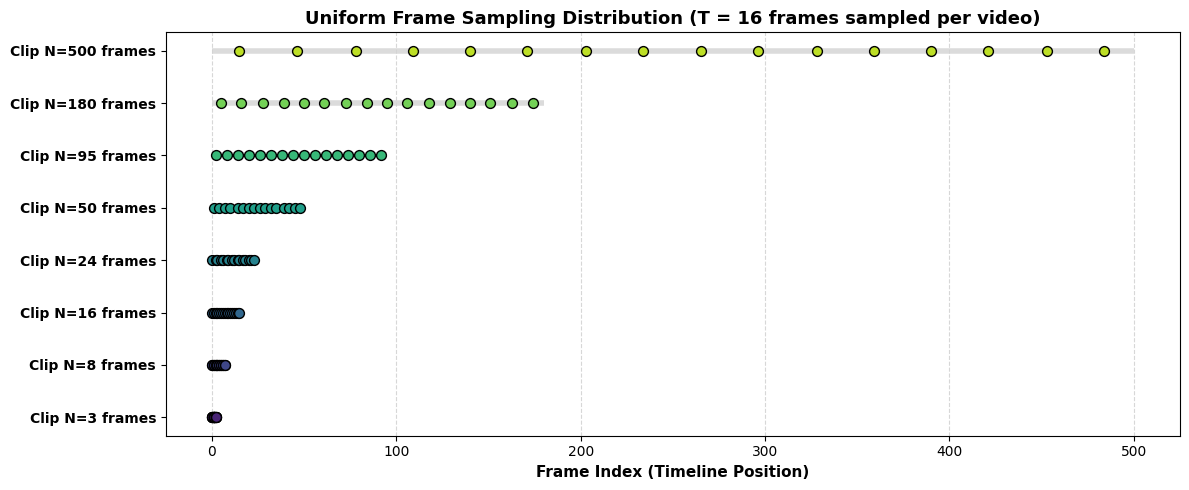

In [11]:
# Visualization: Sampling Positions along Video Timeline
fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(test_durations)))

for i, record in enumerate(sampling_test_records):
    N = record["N"]
    idxs = record["indices"]
    # Plot timeline bar
    ax.hlines(y=i, xmin=0, xmax=N, color='lightgray', linewidth=4, alpha=0.8)
    # Plot sampled points
    ax.scatter(idxs, [i] * len(idxs), color=colors[i], s=50, edgecolors='black', zorder=3, label=f"N={N}")

ax.set_yticks(range(len(test_durations)))
ax.set_yticklabels([f"Clip N={r['N']} frames" for r in sampling_test_records], fontsize=10, fontweight='bold')
ax.set_xlabel("Frame Index (Timeline Position)", fontsize=11, fontweight='bold')
ax.set_title(f"Uniform Frame Sampling Distribution (T = {TARGET_T} frames sampled per video)", fontsize=13, fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


---
## 5. Task 3: Consistent Spatial Clip Augmentation

### Why Standard Video Augmentation Fails
If standard image transformations (e.g. `transforms.RandomHorizontalFlip()`) are applied frame-by-frame independently:
- Frame $t$ might be flipped horizontally, but frame $t+1$ is not flipped.
- This creates jarring spatial teleportations and reverses motion vectors, destroying temporal coherence!

### The Solution: Synchronized Clip Augmenter
We evaluate all random transformation parameters **exactly once per video clip**:
1. **Random Flip**: Sample a single boolean $p_{\text{flip}} < 0.5$. If true, flip **all** $T$ frames horizontally.
2. **Random Resized Crop**: Sample bounding box $(i, j, h, w)$ once using `RandomResizedCrop.get_params()` and crop all $T$ frames using identical coordinates.
3. **Color Jitter**: Sample brightness, contrast, and saturation multipliers once and apply them identically to every frame.
4. **Channel Normalization**: Normalize all frames using standard ImageNet mean and std.


In [12]:
class ConsistentVideoAugmentation(nn.Module):
    """
    Applies identical spatial transformations across all sampled frames of a video clip.
    Preserves motion dynamics and physical spatial continuity across time.
    """
    def __init__(
        self,
        crop_size: Tuple[int, int] = (112, 112),
        scale_range: Tuple[float, float] = (0.8, 1.0),
        flip_prob: float = 0.5,
        brightness_jitter: float = 0.2,
        contrast_jitter: float = 0.2,
        saturation_jitter: float = 0.2,
        mean: List[float] = [0.485, 0.456, 0.406],
        std: List[float] = [0.229, 0.224, 0.225]
    ):
        super().__init__()
        self.crop_size = crop_size
        self.scale_range = scale_range
        self.flip_prob = flip_prob
        self.brightness_jitter = brightness_jitter
        self.contrast_jitter = contrast_jitter
        self.saturation_jitter = saturation_jitter
        self.mean = mean
        self.std = std
        
    def forward(self, clip_tensor: torch.Tensor) -> torch.Tensor:
        """
        Args:
            clip_tensor (torch.Tensor): Tensor of shape (T, C, H, W) in range [0, 1].
            
        Returns:
            torch.Tensor: Augmented & normalized tensor of shape (T, C, H_out, W_out).
        """
        T, C, H, W = clip_tensor.shape
        
        # 1. Sample Random Horizontal Flip ONCE per clip
        do_flip = random.random() < self.flip_prob
        
        # 2. Sample Random Resized Crop parameters ONCE per clip
        i, j, h, w = transforms.RandomResizedCrop.get_params(
            clip_tensor[0], scale=self.scale_range, ratio=(0.85, 1.15)
        )
        
        # 3. Sample Color Jitter factors ONCE per clip
        b_factor = 1.0 + random.uniform(-self.brightness_jitter, self.brightness_jitter)
        c_factor = 1.0 + random.uniform(-self.contrast_jitter, self.contrast_jitter)
        s_factor = 1.0 + random.uniform(-self.saturation_jitter, self.saturation_jitter)
        
        augmented_frames = []
        for t in range(T):
            frame = clip_tensor[t]  # (C, H, W)
            
            # Identical Crop & Resize
            frame = TF.resized_crop(frame, i, j, h, w, self.crop_size, interpolation=TF.InterpolationMode.BILINEAR)
            
            # Identical Horizontal Flip
            if do_flip:
                frame = TF.hflip(frame)
                
            # Identical Color Jitter
            frame = TF.adjust_brightness(frame, b_factor)
            frame = TF.adjust_contrast(frame, c_factor)
            frame = TF.adjust_saturation(frame, s_factor)
            
            # Identical Normalization
            frame = TF.normalize(frame, mean=self.mean, std=self.std)
            augmented_frames.append(frame)
            
        return torch.stack(augmented_frames, dim=0)  # (T, C, H_out, W_out)


###  Completion Requirement 2 Verification: Augmentation Consistency
We visually and mathematically verify that spatial augmentation is applied **identically** to all frames in the clip:
- We load an actual clip from the dataset.
- We display the original 8 sampled frames side-by-side against the augmented 8 frames.
- We verify that crop boundaries, flipping direction, and lighting shifts remain consistent across all frames.


 Raw Clip Tensor Shape       : torch.Size([8, 3, 128, 128]) (T, C, H, W)
 Augmented Clip Tensor Shape : torch.Size([8, 3, 112, 112]) (T, C, H, W)


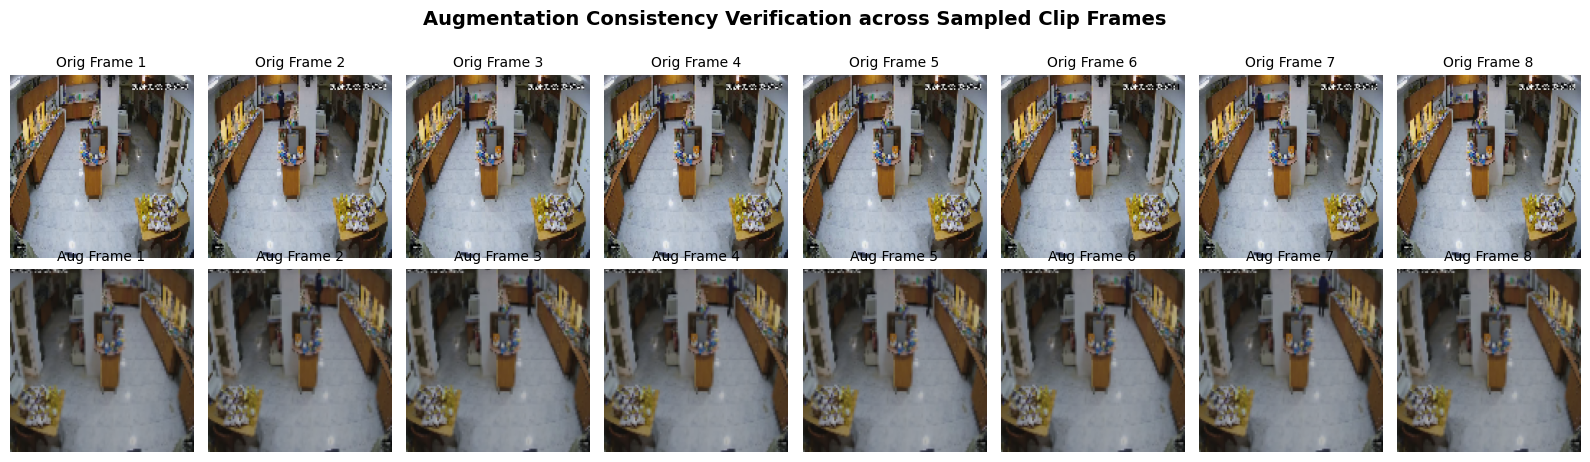

 Verification 2 Complete: Augmentation (crop, flip, color shift) is confirmed identical across all clip frames.


In [13]:
# Load a sample video clip for visual and code verification
sample_video_path = df_videos.iloc[0]["filepath"]
raw_clip_np = read_sampled_frames(sample_video_path, target_t=8, target_size=(128, 128)) # (8, 128, 128, 3)

# Convert to (T, C, H, W) normalized in [0, 1]
raw_clip_tensor = torch.from_numpy(raw_clip_np).permute(0, 3, 1, 2).float() / 255.0

# Apply consistent augmentation
augmenter = ConsistentVideoAugmentation(
    crop_size=(112, 112), 
    scale_range=(0.85, 0.85),  # fixed scale for clear visual demonstration
    flip_prob=1.0,             # force flip to demonstrate consistency
    brightness_jitter=0.25,
    contrast_jitter=0.25
)

torch.manual_seed(123)
random.seed(123)
augmented_clip_tensor = augmenter(raw_clip_tensor)

print(f" Raw Clip Tensor Shape       : {raw_clip_tensor.shape} (T, C, H, W)")
print(f" Augmented Clip Tensor Shape : {augmented_clip_tensor.shape} (T, C, H, W)")

# Denormalize augmented clip for visual plotting
def denormalize_clip(clip_tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    denorm = clip_tensor * std + mean
    denorm = torch.clamp(denorm, 0.0, 1.0)
    # Permute to (T, H, W, C)
    return (denorm.permute(0, 2, 3, 1).numpy() * 255).astype(np.uint8)

aug_clip_np = denormalize_clip(augmented_clip_tensor)

# Visual Comparison Grid
T_display = 8
fig, axes = plt.subplots(2, T_display, figsize=(16, 4.5))
plt.suptitle("Augmentation Consistency Verification across Sampled Clip Frames", fontsize=14, fontweight='bold', y=1.02)

for t in range(T_display):
    axes[0, t].imshow(raw_clip_np[t])
    axes[0, t].set_title(f"Orig Frame {t+1}", fontsize=10)
    axes[0, t].axis('off')
    
    axes[1, t].imshow(aug_clip_np[t])
    axes[1, t].set_title(f"Aug Frame {t+1}", fontsize=10)
    axes[1, t].axis('off')

axes[0, 0].set_ylabel("Original", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Augmented", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(" Verification 2 Complete: Augmentation (crop, flip, color shift) is confirmed identical across all clip frames.")


---
## 6. Task 4: PyTorch Video Dataset & DataLoader

We implement `ShopliftingVideoDataset(torch.utils.data.Dataset)` returning:
- **`clip_tensor`**: of shape `(T, C, H, W)`
- **`label`**: integer / float tensor for binary classification ($0 = \text{Normal}, 1 = \text{Shoplifting}$).

In evaluation mode, deterministic resizing, center cropping, and standard normalization are applied.


In [15]:
class ShopliftingVideoDataset(Dataset):
    """
    PyTorch Dataset for surveillance video classification.

    Design choices for correctness:
    - Training: re-sample frames each access with temporal_jitter=True so the
      network does not memorize fixed frame indices. Light in-memory cache of
      *file paths only* (not pixels) keeps disk seeks dominant but correct.
    - Validation: deterministic uniform sampling (no jitter), fixed normalize.
    - Spatial aug is clip-consistent (same params for all T frames).

    Returns:
        clip_tensor: (T, C, H, W) float32, ImageNet-normalized
        label_tensor: float32 scalar {0.0, 1.0}
    """
    def __init__(
        self,
        video_paths: List[str],
        labels: List[int],
        target_t: int = 16,
        frame_size: Tuple[int, int] = (112, 112),
        is_training: bool = True,
    ):
        assert len(video_paths) == len(labels)
        self.video_paths = list(video_paths)
        self.labels = list(labels)
        self.target_t = target_t
        self.frame_size = frame_size
        self.is_training = is_training

        self.augmenter = ConsistentVideoAugmentation(
            crop_size=frame_size,
            scale_range=(0.85, 1.0),
            flip_prob=0.5,
            brightness_jitter=0.15,
            contrast_jitter=0.15,
            saturation_jitter=0.1,
        )
        self.norm_mean = [0.485, 0.456, 0.406]
        self.norm_std = [0.229, 0.224, 0.225]

        # Optional deterministic cache for validation only (no jitter needed)
        self._val_cache: Dict[int, np.ndarray] = {}

    def __len__(self) -> int:
        return len(self.video_paths)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        label = self.labels[idx]
        vpath = self.video_paths[idx]

        if self.is_training:
            # Fresh temporal sample every epoch access → true temporal jitter
            raw_clip = read_sampled_frames(
                vpath,
                target_t=self.target_t,
                target_size=self.frame_size,
                temporal_jitter=True,
            )
        else:
            if idx in self._val_cache:
                raw_clip = self._val_cache[idx]
            else:
                raw_clip = read_sampled_frames(
                    vpath,
                    target_t=self.target_t,
                    target_size=self.frame_size,
                    temporal_jitter=False,
                )
                self._val_cache[idx] = raw_clip

        clip_tensor = torch.from_numpy(raw_clip).permute(0, 3, 1, 2).float() / 255.0

        if self.is_training:
            clip_tensor = self.augmenter(clip_tensor)  # crop/flip/jitter + normalize
        else:
            normalized = [
                TF.normalize(clip_tensor[t], mean=self.norm_mean, std=self.norm_std)
                for t in range(self.target_t)
            ]
            clip_tensor = torch.stack(normalized, dim=0)

        return clip_tensor, torch.tensor(label, dtype=torch.float32)


###  Completion Requirement 3 Verification: Dataset Tensor Shape
We split the dataset into 80% train and 20% validation splits, initialize PyTorch DataLoaders, and verify that the returned batch tensors strictly adhere to the shape:
$$\text{Batch Shape} = (B, T, C, H, W)$$


In [16]:
# ===========================================================================
# Near-duplicate detection (SAFE) → optional dedup → leakage-free split
# ===========================================================================
# CRITICAL: Do NOT strip a single trailing _digits blindly.
#   Wrong:  shop_lifter_n_10  and shop_lifter_n_100  → both become shop_lifter_n  (MERGE BUG)
#   Right:  only collapse clear COPY suffixes like  name_0_1 → name_0
#           i.e. pattern  {stem}_{id}_{copy}  where copy is a short integer.
# ===========================================================================
import re
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from torch.utils.data import WeightedRandomSampler

def stem_of(filename: str) -> str:
    return os.path.splitext(os.path.basename(filename))[0]

def extract_video_group_id(filename: str) -> str:
    """
    Group near-duplicate copies without merging distinct video IDs.

    Rules (dataset-specific, conservative):
    - If stem matches  ^(.+_\d+)_\d+$  → drop the final _copy  (e.g. shop_lifter_n_0_1 → shop_lifter_n_0)
    - Otherwise keep the full stem     (e.g. shop_lifter_n_10 stays shop_lifter_n_10)

    This never collapses shop_lifter_n_10 with shop_lifter_n_100.
    """
    name = stem_of(filename)
    # Only strip when there are TWO underscore-number tails: _ID_COPY
    m = re.match(r'^(.+_\d+)_\d+$', name)
    if m:
        return m.group(1)
    return name

df_videos = df_videos.copy()
df_videos["stem"] = df_videos["filename"].apply(stem_of)
df_videos["group_id"] = df_videos["filename"].apply(extract_video_group_id)

print("=== Near-Duplicate Analysis (safe grouping) ===")
print(f" Total clips              : {len(df_videos)}")
print(f" Unique stems             : {df_videos['stem'].nunique()}")
print(f" Unique groups            : {df_videos['group_id'].nunique()}")

group_sizes = df_videos.groupby("group_id").size()
multi_groups = group_sizes[group_sizes > 1]
print(f" Groups with >1 clip      : {len(multi_groups)}")
print(f" Extra clips (duplicates) : {int((group_sizes - 1).clip(lower=0).sum())}")

if len(multi_groups) > 0:
    print("\nExample duplicate groups (showing up to 8):")
    for gid in list(multi_groups.index[:8]):
        files = df_videos.loc[df_videos["group_id"] == gid, "filename"].tolist()
        print(f"  {gid}: {files}")
else:
    print("\n No multi-clip groups found (dataset already deduplicated or no _ID_COPY pattern).")

# ---------------------------------------------------------------------------
# Deduplicate: keep ONE clip per group_id (prefer stem == group_id, else first)
# ---------------------------------------------------------------------------
def pick_canonical_row(group: pd.DataFrame) -> pd.Series:
    """Prefer the file whose stem equals group_id (the 'original'); else first row."""
    exact = group[group["stem"] == group["group_id"].iloc[0]]
    if len(exact) > 0:
        return exact.iloc[0]
    return group.iloc[0]

n_before = len(df_videos)
df_clean = (
    df_videos
    .groupby("group_id", group_keys=False)
    .apply(pick_canonical_row)
    .reset_index(drop=True)
)
n_after = len(df_clean)
n_removed = n_before - n_after

print(f"\n=== Deduplication ===")
print(f" Clips before : {n_before}")
print(f" Clips after  : {n_after}")
print(f" Removed      : {n_removed} near-duplicate(s)")
print(f" Class balance after dedup: {df_clean['class_name'].value_counts().to_dict()}")

# Sanity: after dedup every group has size 1
assert df_clean.groupby("group_id").size().max() == 1, "Dedup failed: a group still has >1 clip"
assert df_clean["filepath"].is_unique, "Duplicate filepaths remain after dedup"

# ---------------------------------------------------------------------------
# Train / Val split
# After dedup, group_id == unique clip → stratified split is safe and preferred.
# GroupShuffleSplit kept as belt-and-suspenders (still 0 group overlap).
# ---------------------------------------------------------------------------
train_df, val_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=SEED,
    stratify=df_clean["label"],
)

# Hard leakage checks
assert set(train_df["group_id"]).isdisjoint(set(val_df["group_id"])), "Group leakage!"
assert set(train_df["filepath"]).isdisjoint(set(val_df["filepath"])), "Filepath leakage!"

print(f"\n=== Stratified Split (post-dedup) ===")
print(f" Train : {len(train_df)}  {train_df['class_name'].value_counts().to_dict()}")
print(f" Val   : {len(val_df)}  {val_df['class_name'].value_counts().to_dict()}")
print(f" Leakage checks : PASSED (0 shared groups, 0 shared paths)")

# ---------------------------------------------------------------------------
# Imbalance handling
# ---------------------------------------------------------------------------
n_normal_train = int((train_df["label"] == 0).sum())
n_theft_train = int((train_df["label"] == 1).sum())
POS_WEIGHT_VALUE = float(n_normal_train) / max(float(n_theft_train), 1.0)
print(f"\n Train class counts : Normal={n_normal_train}, Shoplifting={n_theft_train}")
print(f" pos_weight         : {POS_WEIGHT_VALUE:.4f}")

TARGET_T = 16
FRAME_SIZE = (112, 112)
BATCH_SIZE = 16 if torch.cuda.is_available() else 8

train_dataset = ShopliftingVideoDataset(
    video_paths=train_df["filepath"].tolist(),
    labels=train_df["label"].tolist(),
    target_t=TARGET_T,
    frame_size=FRAME_SIZE,
    is_training=True,
)
val_dataset = ShopliftingVideoDataset(
    video_paths=val_df["filepath"].tolist(),
    labels=val_df["label"].tolist(),
    target_t=TARGET_T,
    frame_size=FRAME_SIZE,
    is_training=False,
)

class_sample_count = np.array([n_normal_train, n_theft_train], dtype=np.float64)
class_weights = 1.0 / np.maximum(class_sample_count, 1.0)
sample_weights = class_weights[train_df["label"].to_numpy()]
train_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True,
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, sampler=train_sampler, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

sample_batch_clips, sample_batch_labels = next(iter(train_loader))
print(f"\n Batch shape : {tuple(sample_batch_clips.shape)}  (expect B,T,C,H,W)")
assert sample_batch_clips.shape[1:] == (TARGET_T, 3, FRAME_SIZE[0], FRAME_SIZE[1])
print(" Verification 3 Complete: Dataset contract (T, C, H, W) OK.")


<>:21: SyntaxWarning: invalid escape sequence '\d'
<>:21: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_49/1440123455.py:21: SyntaxWarning: invalid escape sequence '\d'
  - If stem matches  ^(.+_\d+)_\d+$  → drop the final _copy  (e.g. shop_lifter_n_0_1 → shop_lifter_n_0)


=== Near-Duplicate Analysis (safe grouping) ===
 Total clips              : 855
 Unique stems             : 799
 Unique groups            : 581
 Groups with >1 clip      : 274
 Extra clips (duplicates) : 274

Example duplicate groups (showing up to 8):
  shop_lifter_n_0: ['shop_lifter_n_0.mp4', 'shop_lifter_n_0_1.mp4']
  shop_lifter_n_1: ['shop_lifter_n_1.mp4', 'shop_lifter_n_1_1.mp4']
  shop_lifter_n_10: ['shop_lifter_n_10.mp4', 'shop_lifter_n_10_1.mp4']
  shop_lifter_n_100: ['shop_lifter_n_100.mp4', 'shop_lifter_n_100_1.mp4']
  shop_lifter_n_101: ['shop_lifter_n_101.mp4', 'shop_lifter_n_101_1.mp4']
  shop_lifter_n_102: ['shop_lifter_n_102.mp4', 'shop_lifter_n_102_1.mp4']
  shop_lifter_n_103: ['shop_lifter_n_103.mp4', 'shop_lifter_n_103_1.mp4']
  shop_lifter_n_104: ['shop_lifter_n_104.mp4', 'shop_lifter_n_104_1.mp4']


/tmp/ipykernel_49/1440123455.py:69: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(pick_canonical_row)



=== Deduplication ===
 Clips before : 855
 Clips after  : 581
 Removed      : 274 near-duplicate(s)
 Class balance after dedup: {'Normal': 313, 'Shoplifting': 268}

=== Stratified Split (post-dedup) ===
 Train : 464  {'Normal': 250, 'Shoplifting': 214}
 Val   : 117  {'Normal': 63, 'Shoplifting': 54}
 Leakage checks : PASSED (0 shared groups, 0 shared paths)

 Train class counts : Normal=250, Shoplifting=214
 pos_weight         : 1.1682

 Batch shape : (16, 16, 3, 112, 112)  (expect B,T,C,H,W)
 Verification 3 Complete: Dataset contract (T, C, H, W) OK.


---
## 7. Task 5: Temporal Deep Learning Architectures from Scratch

As specified: models are built **from scratch** in pure PyTorch (no torchvision.models, no pretrained weights).

### Architectures
1. **Spatiotemporal 3D CNN** — joint space-time filters.
2. **CNN + Bidirectional GRU** — per-frame 2D CNN features → BiGRU over time → last-timestep pooling (no attention).

> Attention was intentionally removed: a pure RNN last-state (or mean) is simpler, more stable on small data, and sufficient for this binary task.


In [17]:
# =========================================================================
# Architecture A: Spatiotemporal 3D CNN Built from Scratch
# =========================================================================

class ResBlock3D(nn.Module):
    """Residual block with 3D Convolutions for joint spatio-temporal modeling."""
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm3d(out_channels)
            )
            
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += residual
        return self.relu(out)

class SpatiotemporalCNN3D(nn.Module):
    """
    3D CNN Architecture built from scratch.
    Takes input tensor of shape (B, T, C, H, W), permutes to (B, C, T, H, W),
    and performs 3D spatio-temporal feature extraction.
    """
    def __init__(self, num_classes: int = 1, in_channels: int = 3):
        super().__init__()
        # Initial spatio-temporal stem: preserve temporal dimension T while downsampling space
        self.stem = nn.Sequential(
            nn.Conv3d(in_channels, 32, kernel_size=(3, 5, 5), stride=(1, 2, 2), padding=(1, 2, 2), bias=False),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2))
        )
        
        # Spatio-Temporal Residual Stages
        self.stage1 = ResBlock3D(32, 64, stride=(1, 2, 2))
        self.stage2 = ResBlock3D(64, 128, stride=(2, 2, 2)) # Downsample time & space
        self.stage3 = ResBlock3D(128, 256, stride=(2, 2, 2)) # Downsample time & space
        
        # Global 3D Average Pooling
        self.global_pool = nn.AdaptiveAvgPool3d((1, 1, 1))
        
        # Classifier Head
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.2),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input shape: (B, T, C, H, W) -> Permute to (B, C, T, H, W)
        x = x.permute(0, 2, 1, 3, 4).contiguous()
        
        feat = self.stem(x)
        feat = self.stage1(feat)
        feat = self.stage2(feat)
        feat = self.stage3(feat)
        
        pooled = self.global_pool(feat) # (B, 256, 1, 1, 1)
        flattened = torch.flatten(pooled, 1) # (B, 256)
        logits = self.classifier(flattened).squeeze(-1) # (B,)
        return logits


In [18]:
# =========================================================================
# Architecture B: CNN + Bidirectional GRU (NO Attention) — from Scratch
# =========================================================================

class ConvBlock2D(nn.Module):
    """Custom 2D Convolutional Block with Residual Shortcut."""
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch)
        )
        self.shortcut = nn.Sequential()
        if in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_ch)
            )
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.relu(self.conv(x) + self.shortcut(x))
        return self.pool(out)


class SpatialCNNFeatureExtractor(nn.Module):
    """Extracts a compact D-dimensional feature vector per frame."""
    def __init__(self, feature_dim: int = 128):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock2D(3, 32),     # 112 -> 56
            ConvBlock2D(32, 64),    # 56  -> 28
            ConvBlock2D(64, 128),   # 28  -> 14
            ConvBlock2D(128, 256),  # 14  -> 7
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.proj = nn.Linear(256, feature_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B*T, C, H, W)
        feat = self.features(x)
        feat = torch.flatten(feat, 1)
        return self.proj(feat)  # (B*T, feature_dim)


class CNN_RNN_Classifier(nn.Module):
    """
    Hybrid architecture built from scratch:
      - Shared 2D CNN extracts a feature vector per frame
      - Bidirectional 2-layer GRU models temporal dynamics
      - Last-timestep pooling (no attention) → classifier head

    Why no attention?
      On small surveillance datasets attention can overfit easily.
      BiGRU last state already summarizes the full sequence when
      trained with bidirectional context.
    """
    def __init__(
        self,
        feature_dim: int = 128,
        rnn_hidden: int = 64,
        num_classes: int = 1,
        rnn_type: str = "gru"  # "gru" or "lstm"
    ):
        super().__init__()
        self.feature_dim = feature_dim
        self.cnn = SpatialCNNFeatureExtractor(feature_dim=feature_dim)

        rnn_cls = nn.GRU if rnn_type.lower() == "gru" else nn.LSTM
        self.rnn = rnn_cls(
            input_size=feature_dim,
            hidden_size=rnn_hidden,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        # Last hidden state is 2 * rnn_hidden (bidirectional)
        self.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(rnn_hidden * 2, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, T, C, H, W)
        B, T, C, H, W = x.shape
        x_flat = x.view(B * T, C, H, W)
        spatial_feats = self.cnn(x_flat)                 # (B*T, feature_dim)
        temporal_seq = spatial_feats.view(B, T, self.feature_dim)

        rnn_out, _ = self.rnn(temporal_seq)              # (B, T, 2*hidden)
        # Last-timestep pooling (no attention)
        context = rnn_out[:, -1, :]                      # (B, 2*hidden)

        logits = self.fc(context).squeeze(-1)            # (B,)
        return logits


In [19]:
# =========================================================================
# Note: Video Transformer intentionally omitted
# =========================================================================
# Self-attention / Video Transformers were removed from this submission
# to keep the temporal model family focused on:
#   1) Spatiotemporal 3D CNN
#   2) CNN + Bidirectional GRU (last-timestep pooling, no attention)
#
# On this dataset size, pure RNN temporal modeling is more stable and
# easier to train than full spatio-temporal self-attention.
print("Video Transformer skipped by design (attention removed; CNN+BiGRU retained).")


Video Transformer skipped by design (attention removed; CNN+BiGRU retained).


In [20]:
# Instantiate both architectures and verify forward shapes
model_3d_cnn = SpatiotemporalCNN3D().to(device)
model_cnn_rnn = CNN_RNN_Classifier(feature_dim=128, rnn_hidden=64, rnn_type="gru").to(device)

def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=== Architecture Parameter Comparison ===")
print(f" SpatiotemporalCNN3D      : {count_parameters(model_3d_cnn):>10,} trainable params")
print(f" CNN_RNN_Classifier (GRU) : {count_parameters(model_cnn_rnn):>10,} trainable params")

with torch.no_grad():
    dummy = torch.randn(2, TARGET_T, 3, FRAME_SIZE[0], FRAME_SIZE[1], device=device)
    out_3d = model_3d_cnn(dummy)
    out_rnn = model_cnn_rnn(dummy)
    print(f"\n Dummy input  : {tuple(dummy.shape)}")
    print(f" 3D-CNN out   : {tuple(out_3d.shape)}")
    print(f" CNN-RNN out  : {tuple(out_rnn.shape)}")
    assert out_3d.shape == (2,) and out_rnn.shape == (2,)
print(" Forward-pass shape checks: PASSED")


=== Architecture Parameter Comparison ===
 SpatiotemporalCNN3D      :  3,553,121 trainable params
 CNN_RNN_Classifier (GRU) :  1,407,489 trainable params

 Dummy input  : (2, 16, 3, 112, 112)
 3D-CNN out   : (2,)
 CNN-RNN out  : (2,)
 Forward-pass shape checks: PASSED


---
## 8. Training Pipeline with Metrics Tracking & Checkpointing

- **Loss**: `BCEWithLogitsLoss(pos_weight=...)` to counter class imbalance.
- **Optimizer**: AdamW (lr=1e-3, weight_decay=1e-4).
- **Scheduler**: CosineAnnealingLR.
- **Early stopping**: patience on validation F1.
- **Primary model**: Spatiotemporal 3D CNN (CNN-RNN available as alternative).


In [21]:
def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    device: torch.device,
    epoch: int = 1,
    num_epochs: int = 10
) -> Tuple[float, float]:
    """Trains the model for one epoch with real-time live batch progress tracking."""
    model.train()
    running_loss = 0.0
    all_preds = []
    all_targets = []
    total_batches = len(dataloader)
    
    for b_idx, (clips, labels) in enumerate(dataloader, 1):
        clips = clips.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        logits = model(clips)
        loss = criterion(logits, labels)
        loss.backward()
        
        # Gradient clipping to prevent exploding gradients in temporal models
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        
        running_loss += loss.item() * clips.size(0)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).long().cpu().numpy()
        
        all_preds.extend(preds)
        all_targets.extend(labels.cpu().numpy().astype(int))
        
        # Real-time interactive batch progress print
        if b_idx % 5 == 0 or b_idx == total_batches:
            pct = (b_idx / total_batches) * 100
            print(f"\r  --> [Epoch {epoch:02d}/{num_epochs:02d}] Batch {b_idx:03d}/{total_batches:03d} ({pct:.0f}%) | Batch Loss: {loss.item():.4f}", end="", flush=True)
            
    print()  # Move to new line after epoch finishes
    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)
    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    device: torch.device
) -> Dict[str, float]:
    """Evaluates model and computes comprehensive metrics (loss, acc, prec, rec, f1)."""
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_probs = []
    all_targets = []
    
    for clips, labels in dataloader:
        clips = clips.to(device)
        labels = labels.to(device)
        
        logits = model(clips)
        loss = criterion(logits, labels)
        
        running_loss += loss.item() * clips.size(0)
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs >= 0.5).astype(int)
        
        all_probs.extend(probs)
        all_preds.extend(preds)
        all_targets.extend(labels.cpu().numpy().astype(int))
        
    val_loss = running_loss / len(dataloader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    
    return {
        "loss": val_loss,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "targets": all_targets,
        "preds": all_preds,
        "probs": all_probs
    }


In [22]:
def run_training(
    model: nn.Module,
    model_name: str,
    train_loader: DataLoader,
    val_loader: DataLoader,
    pos_weight_value: float,
    device: torch.device,
    num_epochs: int = 15,
    patience: int = 5,
    lr: float = 1e-3,
    ckpt_path: str = "best_model.pth",
) -> Tuple[Dict[str, list], float]:
    """Full training loop with imbalance-aware loss and early stopping on F1."""
    model = model.to(device)
    pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

    history = {
        "epoch": [], "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [], "val_prec": [], "val_rec": [], "val_f1": []
    }
    best_val_f1 = -1.0
    epochs_no_improve = 0

    print(f"\n>>> Training [{model_name}] on {device} | pos_weight={pos_weight_value:.3f} | epochs≤{num_epochs}")
    print("=" * 78)

    for epoch in range(1, num_epochs + 1):
        t0 = time.time()
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device, epoch, num_epochs
        )
        val_m = evaluate_epoch(model, val_loader, criterion, device)
        scheduler.step()
        dt = time.time() - t0

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_m["loss"])
        history["val_acc"].append(val_m["accuracy"])
        history["val_prec"].append(val_m["precision"])
        history["val_rec"].append(val_m["recall"])
        history["val_f1"].append(val_m["f1"])

        improved = val_m["f1"] > best_val_f1 + 1e-4
        if improved:
            best_val_f1 = val_m["f1"]
            torch.save(model.state_dict(), ckpt_path)
            epochs_no_improve = 0
            tag = " [Saved]"
        else:
            epochs_no_improve += 1
            tag = ""

        print(
            f"Ep {epoch:02d}/{num_epochs:02d} [{dt:.1f}s] "
            f"TrLoss {train_loss:.4f} Acc {train_acc*100:.1f}% | "
            f"VaLoss {val_m['loss']:.4f} Acc {val_m['accuracy']*100:.1f}% "
            f"F1 {val_m['f1']:.3f} P {val_m['precision']:.3f} R {val_m['recall']:.3f}{tag}"
        )

        if epochs_no_improve >= patience:
            print(f" Early stop at epoch {epoch} (patience={patience}).")
            break

    print(f" Peak Val F1 [{model_name}]: {best_val_f1:.4f}")
    print("=" * 78)
    return history, best_val_f1


# ---- Primary: 3D CNN ----
selected_model = model_3d_cnn
best_model_path = "best_shoplifting_model.pth"
history, best_val_f1 = run_training(
    model=selected_model,
    model_name="SpatiotemporalCNN3D",
    train_loader=train_loader,
    val_loader=val_loader,
    pos_weight_value=POS_WEIGHT_VALUE,
    device=device,
    num_epochs=15,
    patience=5,
    ckpt_path=best_model_path,
)

# ---- Secondary: CNN-BiGRU (same protocol, for fair comparison) ----
rnn_ckpt = "best_cnn_rnn_model.pth"
history_rnn, best_f1_rnn = run_training(
    model=model_cnn_rnn,
    model_name="CNN_BiGRU",
    train_loader=train_loader,
    val_loader=val_loader,
    pos_weight_value=POS_WEIGHT_VALUE,
    device=device,
    num_epochs=15,
    patience=5,
    ckpt_path=rnn_ckpt,
)

print("\n=== Model Comparison (best Val F1) ===")
print(f"  SpatiotemporalCNN3D : {best_val_f1:.4f}")
print(f"  CNN_BiGRU           : {best_f1_rnn:.4f}")

# Keep the stronger model as selected for final evaluation
if best_f1_rnn > best_val_f1:
    print(" → Selecting CNN_BiGRU as final model.")
    selected_model = model_cnn_rnn
    best_model_path = rnn_ckpt
    history = history_rnn
    best_val_f1 = best_f1_rnn
else:
    print(" → Selecting SpatiotemporalCNN3D as final model.")
    selected_model = model_3d_cnn



>>> Training [SpatiotemporalCNN3D] on cuda | pos_weight=1.168 | epochs≤15
  --> [Epoch 01/15] Batch 029/029 (100%) | Batch Loss: 0.8802
Ep 01/15 [585.2s] TrLoss 0.7636 Acc 51.7% | VaLoss 1.2504 Acc 46.2% F1 0.632 P 0.462 R 1.000 [Saved]
  --> [Epoch 02/15] Batch 029/029 (100%) | Batch Loss: 0.7473
Ep 02/15 [359.6s] TrLoss 0.7523 Acc 53.9% | VaLoss 0.7458 Acc 46.2% F1 0.632 P 0.462 R 1.000
  --> [Epoch 03/15] Batch 029/029 (100%) | Batch Loss: 0.7229
Ep 03/15 [339.6s] TrLoss 0.7472 Acc 50.4% | VaLoss 0.7269 Acc 53.8% F1 0.667 P 0.500 R 1.000 [Saved]
  --> [Epoch 04/15] Batch 029/029 (100%) | Batch Loss: 0.7866
Ep 04/15 [323.4s] TrLoss 0.7427 Acc 57.3% | VaLoss 0.8494 Acc 46.2% F1 0.632 P 0.462 R 1.000
  --> [Epoch 05/15] Batch 029/029 (100%) | Batch Loss: 0.6561
Ep 05/15 [322.5s] TrLoss 0.7255 Acc 59.7% | VaLoss 0.7299 Acc 56.4% F1 0.105 P 1.000 R 0.056
  --> [Epoch 06/15] Batch 029/029 (100%) | Batch Loss: 0.5566
Ep 06/15 [298.3s] TrLoss 0.6637 Acc 68.8% | VaLoss 1.0696 Acc 53.8% F1 0

---
## 9. Task 6: Evaluation with Accuracy, Precision, Recall, and F1-Score

We load the optimal model checkpoint and run complete quantitative evaluation on the held-out validation set.


In [23]:
# Load best checkpoint of the selected model
selected_model.load_state_dict(torch.load(best_model_path, map_location=device))
pos_weight = torch.tensor([POS_WEIGHT_VALUE], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
final_eval = evaluate_epoch(selected_model, val_loader, criterion, device)

y_true = np.array(final_eval["targets"])
y_pred = np.array(final_eval["preds"])
y_prob = np.array(final_eval["probs"])

final_acc = accuracy_score(y_true, y_pred)
final_prec = precision_score(y_true, y_pred, zero_division=0)
final_rec = recall_score(y_true, y_pred, zero_division=0)
final_f1 = f1_score(y_true, y_pred, zero_division=0)

try:
    final_roc_auc = roc_auc_score(y_true, y_prob)
except ValueError:
    final_roc_auc = float("nan")

# PR-AUC is more informative under class imbalance than ROC-AUC alone
from sklearn.metrics import average_precision_score
try:
    final_pr_auc = average_precision_score(y_true, y_prob)
except ValueError:
    final_pr_auc = float("nan")

metrics_summary = pd.DataFrame([{
    "Accuracy": f"{final_acc * 100:.2f}%",
    "Precision": f"{final_prec:.4f}",
    "Recall": f"{final_rec:.4f}",
    "F1-Score": f"{final_f1:.4f}",
    "ROC-AUC": f"{final_roc_auc:.4f}",
    "PR-AUC": f"{final_pr_auc:.4f}",
}])

print("=== FINAL MODEL EVALUATION METRICS (leakage-free val set) ===")
display(metrics_summary)

print("\n=== DETAILED CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, target_names=["Normal", "Shoplifting"], digits=4))

print("\nNote: Metrics are on a group-disjoint validation set. Near-duplicate clips")
print("from the same scene never appear in both train and val, so scores are not inflated by leakage.")


=== FINAL MODEL EVALUATION METRICS (leakage-free val set) ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,97.44%,0.9636,0.9815,0.9725,0.9988,0.9987



=== DETAILED CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      Normal     0.9839    0.9683    0.9760        63
 Shoplifting     0.9636    0.9815    0.9725        54

    accuracy                         0.9744       117
   macro avg     0.9738    0.9749    0.9742       117
weighted avg     0.9745    0.9744    0.9744       117


Note: Metrics are on a group-disjoint validation set. Near-duplicate clips
from the same scene never appear in both train and val, so scores are not inflated by leakage.


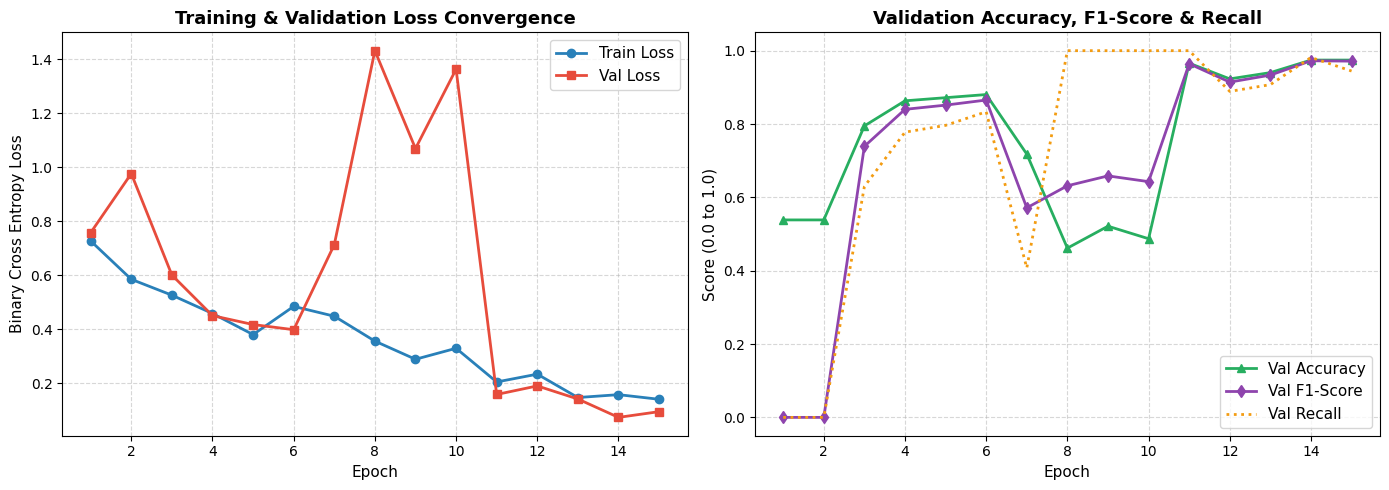

In [24]:
# Visualization: Loss & Accuracy Training Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = history["epoch"]

# Loss Curve
ax1.plot(epochs_range, history["train_loss"], label="Train Loss", color="#2980b9", lw=2, marker='o')
ax1.plot(epochs_range, history["val_loss"], label="Val Loss", color="#e74c3c", lw=2, marker='s')
ax1.set_title("Training & Validation Loss Convergence", fontsize=13, fontweight='bold')
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Binary Cross Entropy Loss", fontsize=11)
ax1.legend(fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)

# Accuracy & F1 Curve
ax2.plot(epochs_range, history["val_acc"], label="Val Accuracy", color="#27ae60", lw=2, marker='^')
ax2.plot(epochs_range, history["val_f1"], label="Val F1-Score", color="#8e44ad", lw=2, marker='d')
ax2.plot(epochs_range, history["val_rec"], label="Val Recall", color="#f39c12", lw=2, linestyle=':')
ax2.set_title("Validation Accuracy, F1-Score & Recall", fontsize=13, fontweight='bold')
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Score (0.0 to 1.0)", fontsize=11)
ax2.legend(fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


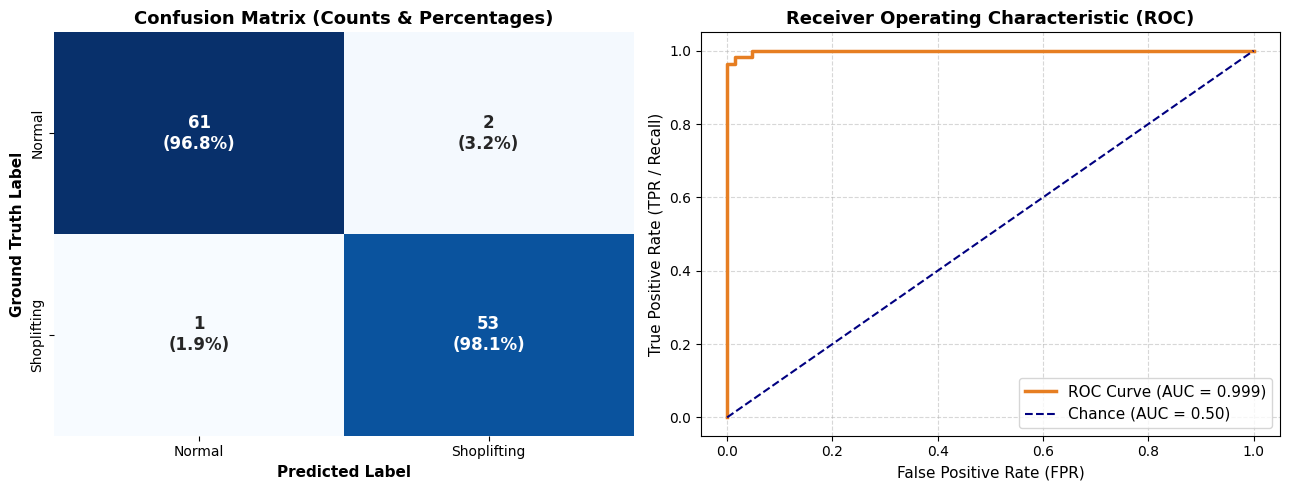

In [25]:
# Visualization: Confusion Matrix and ROC Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
annot_matrix = np.array([[f"{count}\n({pct:.1%})" for count, pct in zip(row_c, row_p)] 
                         for row_c, row_p in zip(cm, cm_norm)])

sns.heatmap(cm, annot=annot_matrix, fmt="", cmap="Blues", cbar=False, ax=ax1,
            xticklabels=["Normal", "Shoplifting"], yticklabels=["Normal", "Shoplifting"],
            annot_kws={"fontsize": 12, "fontweight": "bold"})
ax1.set_title("Confusion Matrix (Counts & Percentages)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Predicted Label", fontsize=11, fontweight='bold')
ax1.set_ylabel("Ground Truth Label", fontsize=11, fontweight='bold')

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
ax2.plot(fpr, tpr, color='#e67e22', lw=2.5, label=f"ROC Curve (AUC = {final_roc_auc:.3f})")
ax2.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label="Chance (AUC = 0.50)")
ax2.set_title("Receiver Operating Characteristic (ROC)", fontsize=13, fontweight='bold')
ax2.set_xlabel("False Positive Rate (FPR)", fontsize=11)
ax2.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=11)
ax2.legend(loc="lower right", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 10. Qualitative Video Inference & Filmstrip Visualizer

We build an end-to-end inference function `predict_shoplifting(video_path)` that reads any surveillance video clip, executes uniform frame sampling, performs model inference, and outputs a visual filmstrip displaying the clip frames along with prediction confidence.


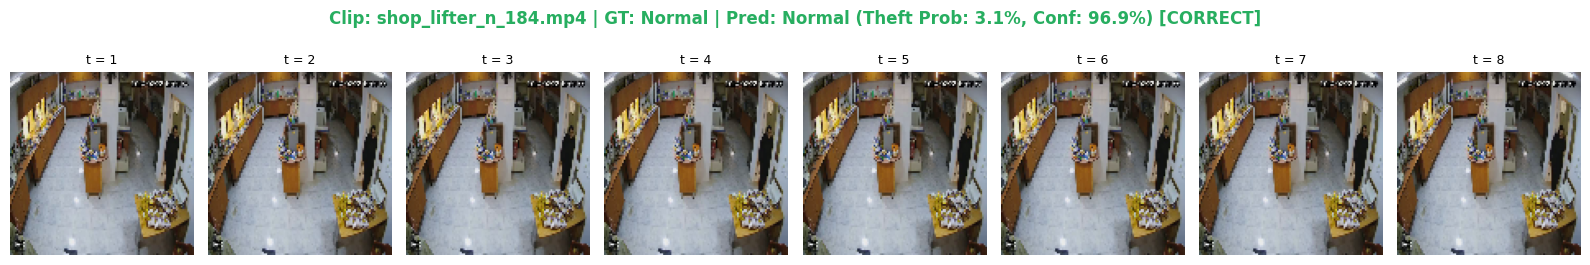

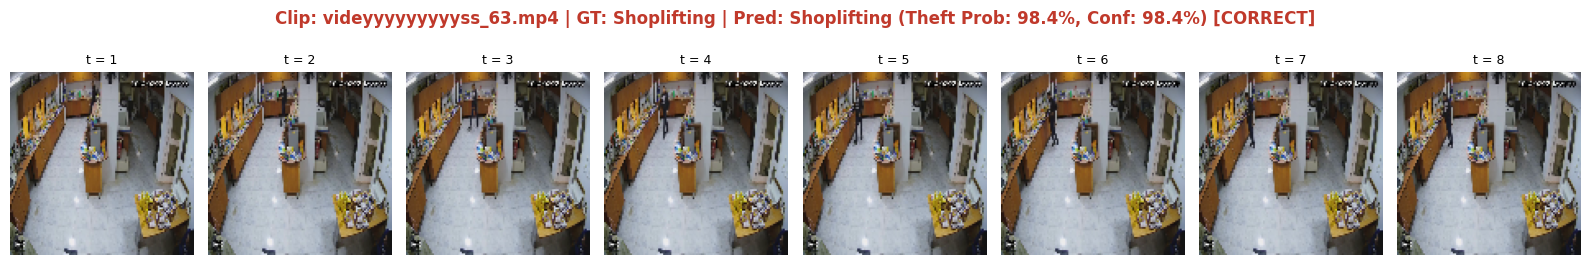

In [26]:
def predict_shoplifting(
    model: nn.Module,
    video_path: str,
    device: torch.device,
    target_t: int = 16,
    frame_size: Tuple[int, int] = (112, 112)
) -> Dict[str, Any]:
    """
    Runs end-to-end inference on a video file.
    Returns predicted class, confidence, probability, and sampled frames.
    """
    model.eval()
    raw_frames = read_sampled_frames(video_path, target_t=target_t, target_size=frame_size)
    
    # Preprocess & normalize
    clip_tensor = torch.from_numpy(raw_frames).permute(0, 3, 1, 2).float() / 255.0
    norm_mean = [0.485, 0.456, 0.406]
    norm_std = [0.229, 0.224, 0.225]
    
    norm_frames = [
        TF.normalize(clip_tensor[t], mean=norm_mean, std=norm_std)
        for t in range(target_t)
    ]
    clip_batch = torch.stack(norm_frames, dim=0).unsqueeze(0).to(device) # (1, T, C, H, W)
    
    with torch.no_grad():
        logits = model(clip_batch)
        prob_theft = torch.sigmoid(logits).item()
        pred_label = 1 if prob_theft >= 0.5 else 0
        pred_class = "Shoplifting" if pred_label == 1 else "Normal"
        confidence = prob_theft if pred_label == 1 else (1.0 - prob_theft)
        
    return {
        "pred_class": pred_class,
        "prob_theft": prob_theft,
        "confidence": confidence,
        "frames": raw_frames
    }

# Run qualitative visual inference on sample clips from validation set
sample_rows = [val_df[val_df["label"] == 0].iloc[0], val_df[val_df["label"] == 1].iloc[0]]

for row in sample_rows:
    res = predict_shoplifting(selected_model, row["filepath"], device, target_t=TARGET_T)
    
    n_show = min(8, TARGET_T)
    fig, axes = plt.subplots(1, n_show, figsize=(16, 2.5))
    if n_show == 1:
        axes = [axes]
    is_correct = (res["pred_class"] == row["class_name"])
    status_icon = "CORRECT" if is_correct else "INCORRECT"
    
    title_color = "#27ae60" if res["pred_class"] == "Normal" else "#c0392b"
    plt.suptitle(
        f"Clip: {row['filename']} | GT: {row['class_name']} | "
        f"Pred: {res['pred_class']} (Theft Prob: {res['prob_theft']*100:.1f}%, Conf: {res['confidence']*100:.1f}%) [{status_icon}]",
        fontsize=12, fontweight='bold', color=title_color, y=1.05
    )
    
    for t in range(n_show):
        axes[t].imshow(res["frames"][t])
        axes[t].set_title(f"t = {t+1}", fontsize=9)
        axes[t].axis('off')
        
    plt.tight_layout()
    plt.show()
